# Flight Delay Analysis Using Python

**Business Problem**

Flight delays can lead to passenger dissatisfaction, missed connections, scheduling disruptions, and increased operational pressure. However, without a detailed analysis of historical flight records, it is difficult to identify recurring delay patterns and determine which routes, airlines, or time periods require closer attention.

We need a Python-based data analysis solution to evaluate flight performance, measure departure and arrival delays, examine cancellation patterns, and investigate relationships between flight distance, airtime, and punctuality.

**Project Requirements**

The analyst is expected to:

1. Clean and prepare the dataset using Pandas and NumPy.
2. Identify missing values, duplicate records, and data-quality issues.
3. Calculate average departure and arrival delays by airline.
4. Identify routes with the highest average delays and most frequent disruptions.
5. Analyze delay patterns by day of the week and scheduled departure time.
6. Calculate flight cancellation rates and compare performance across airlines.
7. Investigate the relationship between departure delays and arrival delays.
8. Examine how flight distance and airtime relate to flight performance.
9. Create clear visualizations using Matplotlib and Seaborn.
10. Present actionable business recommendations based on the analysis.

**Expected Deliverables**

1. A cleaned and analysis-ready dataset
2. A Jupyter Notebook containing Python code and exploratory data analysis.
3. Visualizations highlighting important flight delay patterns.
4. A summary of key findings and business recommendations.
5. An optional machine learning extension to identify flights at higher risk of delay.

**Business Objective**

The final objective is to help airline management identify operational performance gaps, recognize recurring delay patterns, improve resource planning, and make more informed decisions to support better flight punctuality and passenger satisfaction.

In [2]:
# Importing Libraries

import numpy as np 
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

**Importing Data from local machine**

In [3]:
# Importing Data 

flight_data = pd.read_csv("C:\\Users\\Ankit\\OneDrive\\Documents\\Projects\\06 Flight Delay Analysis Using Python\\india_flight_delays_2025.csv")

In [68]:
# Printing Data

flight_data

,FlightDate,Airline,AirlineCode,FlightNumber,Origin,OriginCity,Dest,DestCity,DayOfWeek,CRSDepTime,DepTime,DepDelay,CRSArrTime,ArrTime,ArrDelay,Cancelled,Distance_KM,AirTime_Min
0,2025-01-04,AirAsia India,I5,I5484,LKO,Lucknow,COK,Kochi,Saturday,16:50,18:50,120.0,18:41,20:36,115.0,0,1226,91
1,2025-01-05,Akasa Air,QP,QP921,AMD,Ahmedabad,BLR,Bengaluru,Sunday,12:15,12:17,2.0,13:46,13:48,2.0,0,954,71
2,2025-01-05,Vistara,UK,UK910,HYD,Hyderabad,MAA,Chennai,Sunday,15:50,16:00,10.0,16:49,16:59,10.0,0,520,39
3,2025-01-07,IndiGo,6E,6E477,BOM,Mumbai,JAI,Jaipur,Tuesday,08:30,08:30,0.0,09:54,09:49,-5.0,0,870,64
4,2025-01-09,Air India,AI,AI749,BOM,Mumbai,MAA,Chennai,Thursday,07:30,07:55,25.0,09:06,09:31,25.0,0,1030,76
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
185,2025-09-22,SpiceJet,SG,SG530,JAI,Jaipur,GOI,Goa,Monday,18:15,18:25,10.0,20:15,20:15,0.0,0,1345,100
186,2025-09-23,AirAsia India,I5,I5475,LKO,Lucknow,MAA,Chennai,Tuesday,08:40,08:50,10.0,10:44,11:09,25.0,0,1409,104
187,2025-09-23,Go First,G8,G8930,LKO,Lucknow,DEL,Delhi,Tuesday,14:40,NaN,NaN,15:33,NaN,NaN,1,440,33
188,2025-09-27,Go First,G8,G8167,BOM,Mumbai,JAI,Jaipur,Saturday,17:30,17:30,0.0,18:54,19:04,10.0,0,870,64


## Data Exploration

In [5]:
# Shape of Data

flight_data.shape

(190, 18)

Observation :- This data has **18 Columns** and **190 Rows**

In [6]:
# Number of columns in Data

flight_data.columns

Index(['FlightDate', 'Airline', 'AirlineCode', 'FlightNumber', 'Origin',
       'OriginCity', 'Dest', 'DestCity', 'DayOfWeek', 'CRSDepTime', 'DepTime',
       'DepDelay', 'CRSArrTime', 'ArrTime', 'ArrDelay', 'Cancelled',
       'Distance_KM', 'AirTime_Min'],
      dtype='object')

**Columns Meaning :-** \
\
    **FlightDate** :- Date the flight was scheduled or operated.\
    **Airline**	:- Full name of the airline.\
    **AirlineCode**	:- Short code identifying the airline.\
    **FlightNumber**	:- Number assigned to the flight.\
    **Origin**	:- Code of the departure airport.\
    **OriginCity**	:- City where the flight starts.\
    **Dest** :- Code of the destination airport.\
    **DestCity** :- City where the flight lands.\
    **DayOfWeek**	:- Day of the week, usually represented by a number.\
    **CRSDepTime**	:- Originally scheduled departure time (CRS is stands for **Computer Reservation System**).\
    **DepTime**	:- Actual departure time.\
    **CRSArrTime**	:- Originally scheduled arrival time (CRS is stands for **Computer Reservation System**).\
    **ArrTime**	:- Actual arrival time.\
    **DepDelay**	:- Difference between actual and scheduled departure, in minutes (15 = 15 minutes late).\
    **ArrDelay**	:- Difference between actual and scheduled arrival, in minutes	(10 = 10 minutes late).\
    **Cancelled**	:- Indicates whether the flight was cancelled.\
    **Distance_KM**	:- Distance between the origin and destination, in Kilometres.\
    **AirTime_Min**	:- Time the aircraft spent in the air, in Minutes.
    

In [7]:
# Values Count

flight_data["Airline"].value_counts()

Airline
Air India        34
SpiceJet         30
AirAsia India    28
Akasa Air        25
IndiGo           25
Go First         25
Vistara          23
Name: count, dtype: int64

Observation :- this data has 7 Different Company Flights

In [8]:
# Values Count

flight_data["OriginCity"].value_counts()

OriginCity
Mumbai       55
Delhi        53
Jaipur       13
Hyderabad    11
Bengaluru    10
Goa           9
Lucknow       8
Ahmedabad     8
Kochi         7
Chennai       7
Pune          6
Kolkata       3
Name: count, dtype: int64

Observation :- this data has 12 Cities 

In [9]:
# Values Count

flight_data["DestCity"].value_counts()

DestCity
Chennai      28
Kochi        18
Jaipur       17
Lucknow      17
Kolkata      17
Ahmedabad    17
Goa          16
Pune         15
Bengaluru    13
Hyderabad    12
Delhi        11
Mumbai        9
Name: count, dtype: int64

In [10]:
# Values Count

flight_data["DayOfWeek"].value_counts()

DayOfWeek
Sunday       36
Monday       31
Friday       30
Tuesday      26
Thursday     24
Wednesday    23
Saturday     20
Name: count, dtype: int64

In [11]:
# Values Count

flight_data["Cancelled"].value_counts()

Cancelled
0    185
1      5
Name: count, dtype: int64

Observation :- This data shows 5 Flights have been Cancelled

In [12]:
# Values Count

flight_data["Distance_KM"].value_counts()

Distance_KM
1300    13
440     11
1030     9
1180     9
2130     9
        ..
514      1
832      1
1339     1
901      1
815      1
Name: count, Length: 76, dtype: int64

In [13]:
# Data INFO

flight_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 190 entries, 0 to 189
Data columns (total 18 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   FlightDate    190 non-null    object 
 1   Airline       190 non-null    object 
 2   AirlineCode   190 non-null    object 
 3   FlightNumber  190 non-null    object 
 4   Origin        190 non-null    object 
 5   OriginCity    190 non-null    object 
 6   Dest          190 non-null    object 
 7   DestCity      190 non-null    object 
 8   DayOfWeek     190 non-null    object 
 9   CRSDepTime    190 non-null    object 
 10  DepTime       185 non-null    object 
 11  DepDelay      185 non-null    float64
 12  CRSArrTime    190 non-null    object 
 13  ArrTime       185 non-null    object 
 14  ArrDelay      185 non-null    float64
 15  Cancelled     190 non-null    int64  
 16  Distance_KM   190 non-null    int64  
 17  AirTime_Min   190 non-null    int64  
dtypes: float64(2), int64(3), objec

Observation :- CRSDepTime, DepTime, ArrTime and CRSArrTime are in Object

Solution :- We  can not convert them to float because they represent time so we will leave them as it is

In [14]:
# Total Null Values

flight_data.isnull().sum()

FlightDate      0
Airline         0
AirlineCode     0
FlightNumber    0
Origin          0
OriginCity      0
Dest            0
DestCity        0
DayOfWeek       0
CRSDepTime      0
DepTime         5
DepDelay        5
CRSArrTime      0
ArrTime         5
ArrDelay        5
Cancelled       0
Distance_KM     0
AirTime_Min     0
dtype: int64

In [15]:
# Printing Total Null Values

flight_data[flight_data["DepTime"].isnull().tolist()]

,FlightDate,Airline,AirlineCode,FlightNumber,Origin,OriginCity,Dest,DestCity,DayOfWeek,CRSDepTime,DepTime,DepDelay,CRSArrTime,ArrTime,ArrDelay,Cancelled,Distance_KM,AirTime_Min
10,2025-01-20,Air India,AI,AI338,DEL,Delhi,MAA,Chennai,Monday,06:50,NaN,NaN,09:20,NaN,NaN,1,1760,130
17,2025-01-25,AirAsia India,I5,I5235,COK,Kochi,CCU,Kolkata,Saturday,17:20,NaN,NaN,18:06,NaN,NaN,1,345,26
108,2025-05-29,SpiceJet,SG,SG556,COK,Kochi,HYD,Hyderabad,Thursday,18:15,NaN,NaN,19:35,NaN,NaN,1,812,60
183,2025-09-20,IndiGo,6E,6E826,DEL,Delhi,MAA,Chennai,Saturday,21:50,NaN,NaN,00:20,NaN,NaN,1,1760,130
187,2025-09-23,Go First,G8,G8930,LKO,Lucknow,DEL,Delhi,Tuesday,14:40,NaN,NaN,15:33,NaN,NaN,1,440,33


Observation :- This Observation Shows there are 5 DepTime, 5 DepDelay,5 ArrTime and 5 ArrDelay as null in rows **10, 17, 108, 183 and 187**

Observation :- These 5 Flights  has been Cancelled so there cant be DepTime, DepDelay, ArrTime and ArrDelay

Solution :- Keep them as they are because this data is correct and important

In [16]:
# Total Duplicate Values

flight_data.duplicated().sum()

0

Observation :- No Duplicate Values in This data 

<Axes: xlabel='DepDelay'>

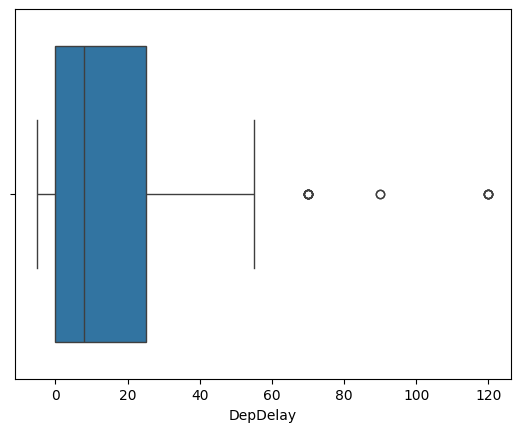

In [17]:
# Boxplot for Departue Delay to Find Outliers

sns.boxplot(x = flight_data["DepDelay"])

Observation :- Departure Delay Shows some outliers for Departure

In [18]:
# Departure Delay Quantile 0.25 and 0.75

DepDelay_Q1 = flight_data["DepDelay"].quantile(0.25)

DepDelay_Q3 = flight_data["DepDelay"].quantile(0.75)

In [19]:
# Departure Delay Inter Quartile Range (DepDelay_IQR)

DepDelay_IQR = DepDelay_Q3 - DepDelay_Q1

In [20]:
# Lower Limit (DepDelay_LL) and Upper Limit (DepDelay_UL) for Departure Delay

DepDelay_LL = DepDelay_Q1 - 1.5 * DepDelay_IQR

DepDelay_UL = DepDelay_Q3 + 1.5 * DepDelay_IQR

In [21]:
# Lower Limit for Departure Delay

DepDelay_LL

-37.5

In [22]:
# Upper Limit for Departure Delay

DepDelay_UL

62.5

In [23]:
# Departure Delayed Outliers shape

flight_data[flight_data["DepDelay"] > DepDelay_UL].shape

(15, 18)

In [24]:
# Departure Delayed Outliers

flight_data[flight_data["DepDelay"] > DepDelay_UL]

,FlightDate,Airline,AirlineCode,FlightNumber,Origin,OriginCity,Dest,DestCity,DayOfWeek,CRSDepTime,DepTime,DepDelay,CRSArrTime,ArrTime,ArrDelay,Cancelled,Distance_KM,AirTime_Min
0,2025-01-04,AirAsia India,I5,I5484,LKO,Lucknow,COK,Kochi,Saturday,16:50,18:50,120.0,18:41,20:36,115.0,0,1226,91
14,2025-01-24,AirAsia India,I5,I5167,LKO,Lucknow,BOM,Mumbai,Friday,19:40,20:50,70.0,21:36,22:36,60.0,0,1300,96
24,2025-01-30,Air India,AI,AI384,BOM,Mumbai,DEL,Delhi,Thursday,19:40,20:50,70.0,21:25,22:45,80.0,0,1150,85
46,2025-02-14,Air India,AI,AI636,DEL,Delhi,HYD,Hyderabad,Friday,11:40,13:40,120.0,13:33,15:33,120.0,0,1260,93
52,2025-02-18,SpiceJet,SG,SG490,DEL,Delhi,BOM,Mumbai,Tuesday,07:50,09:50,120.0,09:35,11:30,115.0,0,1150,85
53,2025-02-18,IndiGo,6E,6E867,DEL,Delhi,BLR,Bengaluru,Tuesday,11:00,12:10,70.0,13:29,14:39,70.0,0,1740,129
102,2025-05-07,Akasa Air,QP,QP310,PNQ,Pune,BOM,Mumbai,Wednesday,09:10,11:10,120.0,09:41,11:56,135.0,0,150,11
104,2025-05-11,AirAsia India,I5,I5153,AMD,Ahmedabad,LKO,Lucknow,Sunday,06:00,08:00,120.0,08:26,10:41,135.0,0,1706,126
107,2025-05-28,SpiceJet,SG,SG953,GOI,Goa,DEL,Delhi,Wednesday,08:15,09:25,70.0,10:26,11:51,85.0,0,1500,111
113,2025-06-11,AirAsia India,I5,I5711,BOM,Mumbai,BLR,Bengaluru,Wednesday,06:40,08:10,90.0,08:02,09:22,80.0,0,840,62


Observation :- Over 15 Flights had Departed Delay for about 70-120 minutes

In [25]:
# Arrival Delayed Outliers

flight_data[flight_data["DepDelay"] < DepDelay_LL]

,FlightDate,Airline,AirlineCode,FlightNumber,Origin,OriginCity,Dest,DestCity,DayOfWeek,CRSDepTime,DepTime,DepDelay,CRSArrTime,ArrTime,ArrDelay,Cancelled,Distance_KM,AirTime_Min


Observation :- No Flights were Departed Too Early

<Axes: xlabel='ArrDelay'>

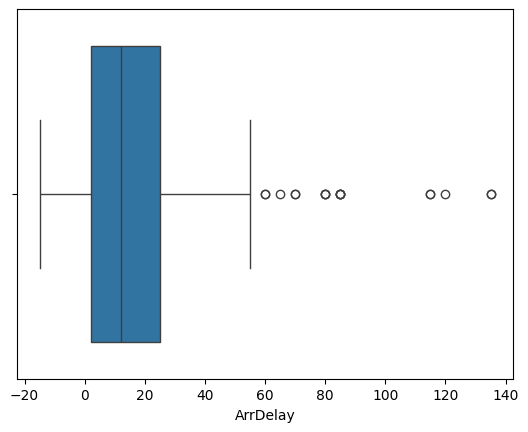

In [26]:
# Boxplot for Arrival Delay to Find Outliers

sns.boxplot(x = flight_data["ArrDelay"])

Observation :- Arrival Delay Shows some outliers for Arrival

In [27]:
# Arrival Delay Quantile 0.25 and 0.75

ArrDelay_Q1 = flight_data["ArrDelay"].quantile(0.25)

ArrDelay_Q3 = flight_data["ArrDelay"].quantile(0.75)

In [28]:
# Arrival Delay Inter Quartile Range (ArrDelay_IQR)

ArrDelay_IQR = ArrDelay_Q3 - ArrDelay_Q1

In [29]:
# Lower Limit (ArrDelay_LL) and Upper Limit (ArrDelay_UL) for arrival Delay

ArrDelay_LL = ArrDelay_Q1 - 1.5 * ArrDelay_IQR

ArrDelay_UL = ArrDelay_Q3 + 1.5 * ArrDelay_IQR

In [30]:
ArrDelay_LL

-32.5

In [31]:
ArrDelay_UL

59.5

In [32]:
## Arrival Delayed Outliers shape

flight_data[flight_data["ArrDelay"] > ArrDelay_UL].shape

(17, 18)

In [33]:
# Arrival Delayed Outliers

flight_data[flight_data["ArrDelay"] > ArrDelay_UL]

,FlightDate,Airline,AirlineCode,FlightNumber,Origin,OriginCity,Dest,DestCity,DayOfWeek,CRSDepTime,DepTime,DepDelay,CRSArrTime,ArrTime,ArrDelay,Cancelled,Distance_KM,AirTime_Min
0,2025-01-04,AirAsia India,I5,I5484,LKO,Lucknow,COK,Kochi,Saturday,16:50,18:50,120.0,18:41,20:36,115.0,0,1226,91
14,2025-01-24,AirAsia India,I5,I5167,LKO,Lucknow,BOM,Mumbai,Friday,19:40,20:50,70.0,21:36,22:36,60.0,0,1300,96
24,2025-01-30,Air India,AI,AI384,BOM,Mumbai,DEL,Delhi,Thursday,19:40,20:50,70.0,21:25,22:45,80.0,0,1150,85
46,2025-02-14,Air India,AI,AI636,DEL,Delhi,HYD,Hyderabad,Friday,11:40,13:40,120.0,13:33,15:33,120.0,0,1260,93
52,2025-02-18,SpiceJet,SG,SG490,DEL,Delhi,BOM,Mumbai,Tuesday,07:50,09:50,120.0,09:35,11:30,115.0,0,1150,85
53,2025-02-18,IndiGo,6E,6E867,DEL,Delhi,BLR,Bengaluru,Tuesday,11:00,12:10,70.0,13:29,14:39,70.0,0,1740,129
82,2025-04-20,Akasa Air,QP,QP367,AMD,Ahmedabad,GOI,Goa,Sunday,11:45,12:40,55.0,14:24,15:24,60.0,0,1871,139
102,2025-05-07,Akasa Air,QP,QP310,PNQ,Pune,BOM,Mumbai,Wednesday,09:10,11:10,120.0,09:41,11:56,135.0,0,150,11
104,2025-05-11,AirAsia India,I5,I5153,AMD,Ahmedabad,LKO,Lucknow,Sunday,06:00,08:00,120.0,08:26,10:41,135.0,0,1706,126
107,2025-05-28,SpiceJet,SG,SG953,GOI,Goa,DEL,Delhi,Wednesday,08:15,09:25,70.0,10:26,11:51,85.0,0,1500,111


Observation :- Over 17 Flights had Arrived Delay for about 60-135 minutes

In [34]:
# Arrival Delayed Outliers

flight_data[flight_data["ArrDelay"] < ArrDelay_LL]

,FlightDate,Airline,AirlineCode,FlightNumber,Origin,OriginCity,Dest,DestCity,DayOfWeek,CRSDepTime,DepTime,DepDelay,CRSArrTime,ArrTime,ArrDelay,Cancelled,Distance_KM,AirTime_Min


Observation :- No Flights were Arriving Too Early

<Axes: xlabel='Distance_KM'>

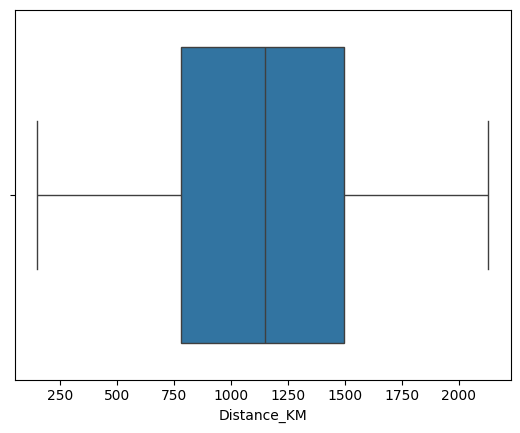

In [35]:
# Boxplot for Distance to Find Outliers

sns.boxplot( x = flight_data["Distance_KM"])

Observation :- No Outliers for Distance_KM

<Axes: xlabel='AirTime_Min'>

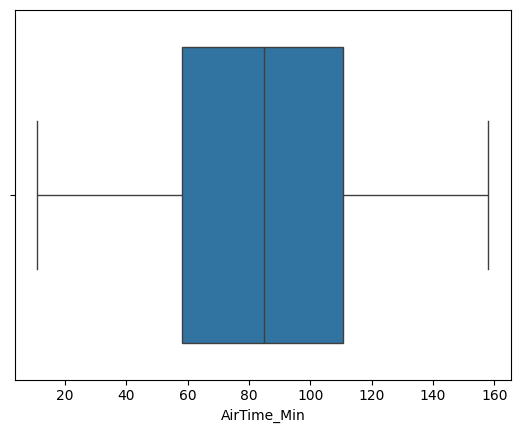

In [36]:
# Boxplot for Airtime of a flight to Find Outliers

sns.boxplot( x = flight_data["AirTime_Min"])

Observation :- No Outliers for AirTime_Min

## Data Cleaning

In [37]:
# Checking Null Values

flight_data.isnull().sum()

FlightDate      0
Airline         0
AirlineCode     0
FlightNumber    0
Origin          0
OriginCity      0
Dest            0
DestCity        0
DayOfWeek       0
CRSDepTime      0
DepTime         5
DepDelay        5
CRSArrTime      0
ArrTime         5
ArrDelay        5
Cancelled       0
Distance_KM     0
AirTime_Min     0
dtype: int64

**Missing Values:** Identified five missing values in each of the `DepTime`, `DepDelay`, `ArrTime`, and `ArrDelay` columns. These missing values correspond to cancelled flights, where actual departure and arrival information was unavailable. Therefore, the missing values were retained without imputation to preserve data accuracy.

In [38]:
# Checking Duplicates 

flight_data.duplicated().sum()

0

**Duplicate Records:** Checked the dataset for duplicate rows using Pandas. No duplicate records were found, so no rows needed to be removed.

In [39]:
# Coverting Flight Dates Data Type From Object to DateType  

flight_data['FlightDate'] = pd.to_datetime(flight_data['FlightDate'], errors='coerce')

In [40]:
# Checking Data Types

flight_data.dtypes

FlightDate      datetime64[ns]
Airline                 object
AirlineCode             object
FlightNumber            object
Origin                  object
OriginCity              object
Dest                    object
DestCity                object
DayOfWeek               object
CRSDepTime              object
DepTime                 object
DepDelay               float64
CRSArrTime              object
ArrTime                 object
ArrDelay               float64
Cancelled                int64
Distance_KM              int64
AirTime_Min              int64
dtype: object

**Data Types :-** Reviewed the data types of all columns to ensure they were appropriate for analysis. Categorical variables, numerical measurements, dates, and time values were identified and assessed. FlightDate was converted to datetime, while the time columns were retained as strings because they represent clock times.

### Data Cleaning

The dataset was inspected to assess data quality and ensure it was suitable for exploratory data analysis (EDA).

The following checks were performed:

1. **Missing Values :-** Checked all columns for null values. Missing departure and arrival details in cancelled flights were retained because these values were not available for flights that did not operate.
2. **Duplicate Records :-** Checked for duplicate rows to identify repeated records.
3. **Data Types :-** Reviewed the data types of all columns to ensure that numerical measurements, categorical variables, dates, and time values were appropriately represented.
4. **Invalid Values :-** Inspected the dataset for incorrect or inconsistent values that could affect the analysis.
5. **Outlier Detection :-** Used box plots and the Interquartile Range (IQR) method to identify potential outliers in departure delay, arrival delay, flight distance, and airtime. Potential outliers were reviewed rather than automatically removed.

**Outcome :-** The dataset was reviewed for common data quality issues. No additional corrections or removals are considered necessary based on the checks performed, and valid observations were retained for further analysis.

In [41]:
# Exporting Cleaned Data 

flight_data.to_excel("Cleaned_india_flight_delays_2025.xlsx")

## Exploratory Data Analysis

In [42]:
# Categorizing Columns

continuous = ["DepDelay", "ArrDelay", "Distance_KM", "AirTime_Min"]

categorical = ["Airline", "AirlineCode", "Origin", "OriginCity", "Dest", "DestCity", "Cancelled", "FlightNumber", "DayOfWeek"]

date = ["FlightDate"]

time = ["CRSDepTime", "DepTime", "CRSArrTime", "ArrTime"]

Note :- Categorizing this data into 4 types continuous, categorical, date and time

### 1. What is the overall flight delay situation ? 
**Answer :-**

In [43]:
# What is the overall flight delay situation ?

flight_data[["DepDelay","ArrDelay"]].describe()

,DepDelay,ArrDelay
count,185.000000,185.000000
mean,16.945946,18.648649
std,26.318437,27.528855
min,-5.000000,-15.000000
25%,0.000000,2.000000
50%,8.000000,12.000000
75%,25.000000,25.000000
max,120.000000,135.000000


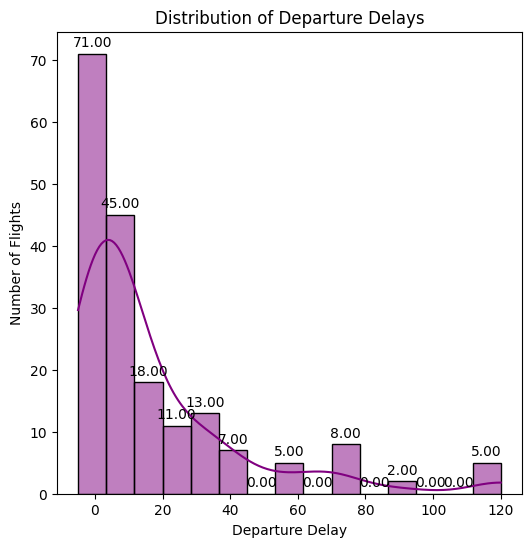

In [44]:
# Distribution of Departure Delays using Histogram

plt.figure(figsize = (6,6))
sns.histplot(flight_data["DepDelay"],kde=True, color='purple', label='Departure Delay')
plt.title("Distribution of Departure Delays")
plt.xlabel("Departure Delay")
plt.ylabel("Number of Flights")
for container in plt.gca().containers:
    plt.gca().bar_label(container, fmt='%.2f', padding=3)
plt.show()

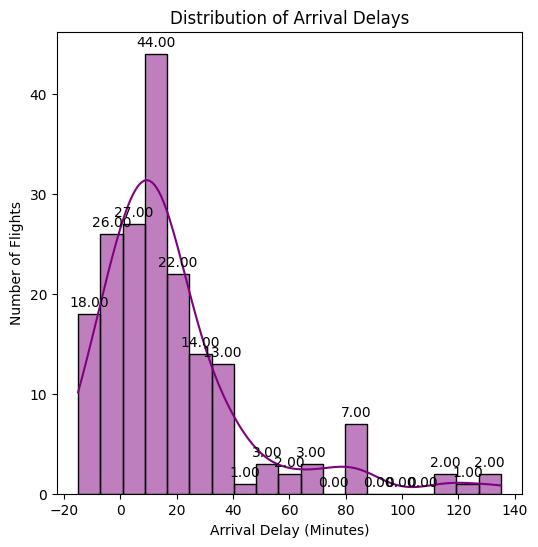

In [70]:
# Distribution of Arrival Delays using Histogram

plt.figure(figsize = (6,6))
sns.histplot(flight_data["ArrDelay"],kde=True, color='purple', label='Arrival Delay')
plt.title("Distribution of Arrival Delays")
plt.xlabel("Arrival Delay (Minutes)")
plt.ylabel("Number of Flights")
for container in plt.gca().containers:
    plt.gca().bar_label(container, fmt='%.2f', padding=3)
plt.show()

**Overall flight delay situation**

Average departure delay :- 16.945946 min \
Average arrival delay :- 18.648649 min \
Maximum departure delays :- 120 min \
Maximum arrival delays :- 135 min

### 2. Which airline has the highest average arrival delay and departure delay ?
**Answer :-**

In [46]:
# Which airline has the highest average arrival delay and departure delay ?

flight_data.groupby("Airline")[["ArrDelay", "DepDelay"]].mean().sort_values(by = ["ArrDelay", "DepDelay"], ascending = False)

,ArrDelay,DepDelay
Airline,,
AirAsia India,26.703704,24.851852
Akasa Air,26.080000,22.280000
SpiceJet,21.413793,18.655172
Air India,20.757576,19.090909
IndiGo,13.458333,13.875000
Go First,11.208333,10.791667
Vistara,7.782609,6.260870


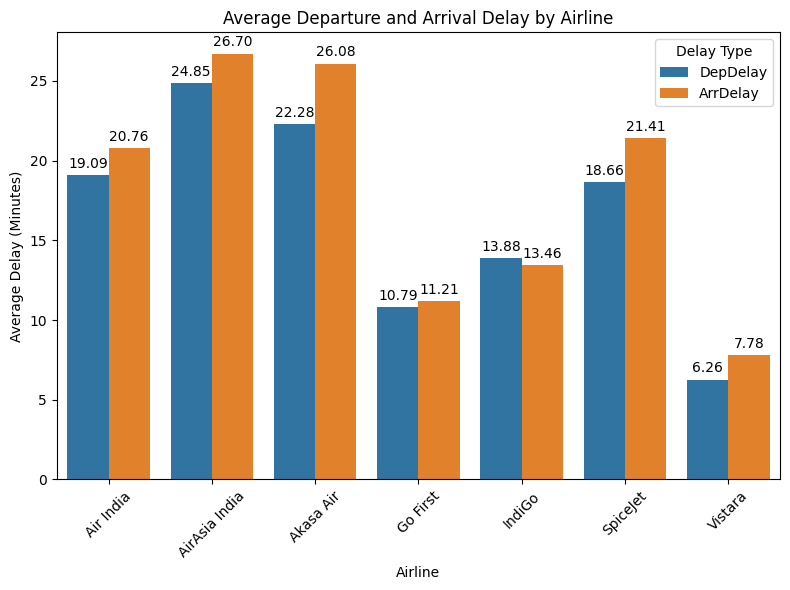

In [67]:
# Average Departure and Arrival Delay by Airline using Grouped Bar chart

airline_delay = flight_data.groupby('Airline')[['DepDelay', 'ArrDelay']].mean().reset_index()

airline_delay = airline_delay.melt(
    id_vars='Airline',
    var_name='Delay Type',
    value_name='Average Delay')

plt.figure(figsize=(8, 6))
sns.barplot(data=airline_delay, x='Airline', y='Average Delay', hue='Delay Type')

plt.title('Average Departure and Arrival Delay by Airline')
plt.xlabel('Airline')
plt.ylabel('Average Delay (Minutes)')
plt.xticks(rotation=45)
plt.tight_layout()
for container in plt.gca().containers:
    plt.gca().bar_label(container, fmt='%.2f', padding=3)
plt.show()

**Highest average arrival delay and departure delay Analysis**

AirAsia India recorded the highest average arrival delay at 26.70 minutes and the highest average departure delay at 24.85 minutes. Akasa Air followed with an average arrival delay of 26.08 minutes. Vistara recorded the lowest average arrival delay at 7.78 minutes and the lowest average departure delay at 6.26 minutes.

**Business Insight:** The differences in average delays suggest that delay patterns vary across airlines. Airlines with higher average delays could investigate operational factors and arrival-delay patterns to identify opportunities for improvement.

### 3. Which day of the week has the highest average delay ?
**Answer :-**

In [48]:
# Which day of the week has the highest average delay ?

flight_data.groupby("DayOfWeek")[["ArrDelay","DepDelay"]].mean().sort_values(by = ["ArrDelay", "DepDelay"], ascending = False)

,ArrDelay,DepDelay
DayOfWeek,,
Wednesday,24.652174,22.913043
Saturday,23.444444,22.888889
Tuesday,18.640000,16.840000
Friday,18.000000,16.666667
Thursday,17.782609,15.391304
Sunday,16.527778,15.138889
Monday,15.033333,12.533333


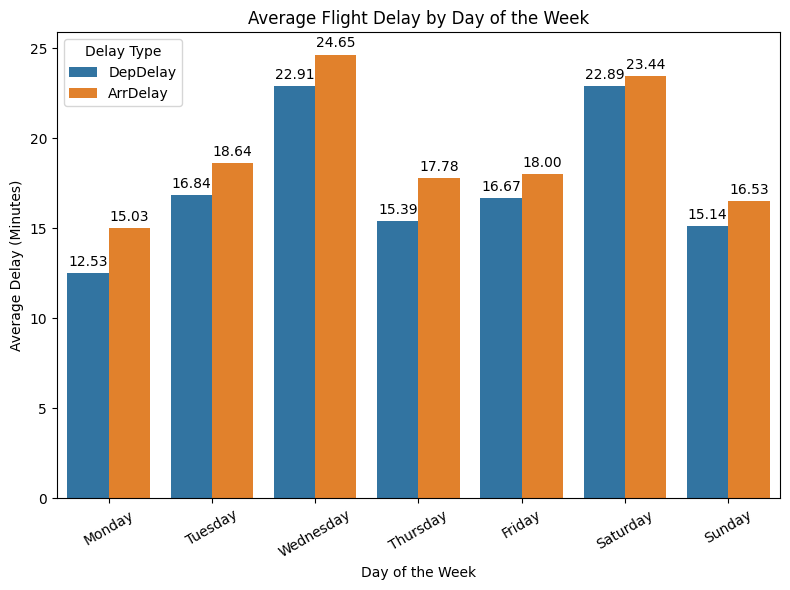

In [49]:
# Creating Groupby  for Day of the Weak by Departure Delay and Arrival Delay
day_delay = flight_data.groupby('DayOfWeek')[ ['DepDelay', 'ArrDelay'] ].mean().reset_index()

# Creating List of Days By the Order
day_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']

# Updating Day_Delay by Correct Order
day_delay['DayOfWeek'] = pd.Categorical(day_delay['DayOfWeek'], categories = day_order, ordered=True )


day_delay = day_delay.sort_values('DayOfWeek')

day_delay = day_delay.melt(id_vars='DayOfWeek', var_name='Delay Type', value_name='Average Delay')


plt.figure(figsize=(8, 6))
sns.barplot(data=day_delay, x='DayOfWeek', y='Average Delay', hue='Delay Type')
plt.title('Average Flight Delay by Day of the Week')
plt.xlabel('Day of the Week')
plt.ylabel('Average Delay (Minutes)')
plt.xticks(rotation=30)
plt.tight_layout()
for container in plt.gca().containers:
    plt.gca().bar_label(container, fmt='%.2f', padding=3)
plt.show()

**Average delay Analysis by day of weak**

The analysis shows that Wednesday recorded the highest average arrival delay at 24.65 minutes and the highest average departure delay at 22.91 minutes. Saturday also experienced substantial delays, with an average arrival delay of 23.44 minutes. Monday recorded the lowest average arrival delay at 15.03 minutes and the lowest average departure delay at 12.53 minutes.

**Business Insight:** Delay patterns vary across weekdays in this dataset. Airlines could investigate Wednesday and Saturday operations to determine whether scheduling, traffic, or other operational factors contribute to the observed delays. These results describe the dataset and do not establish the causes of the delays.

### 4. What percentage of flights were cancelled ?
**Answer :-**

In [50]:
# What percentage of flights were cancelled ?

Cancelle_perc = (flight_data["Cancelled"]==1).value_counts()[True] / len(flight_data) * 100
print("Percentage of flights were Cancelled :- ", Cancelle_perc)

Percentage of flights were Cancelled :-  2.631578947368421


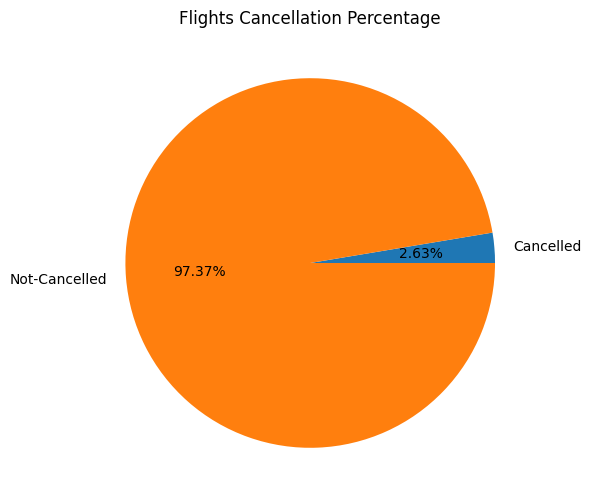

In [69]:
# What percentage of flights were cancelled using pie chart

Cancel_count = flight_data["Cancelled"].value_counts().sort_values()

plt.figure(figsize = (6,6))
plt.pie(Cancel_count, labels = ["Cancelled", "Not-Cancelled"], autopct='%1.2f%%')
plt.title("Flights Cancellation Percentage")
plt.show()

**Flight Cancellation Analysis**

The analysis shows that 2.63% of flights in the dataset were cancelled, while approximately 97.37% were not cancelled.

**Business Insight:** Although cancellations represent a relatively small proportion of the recorded flights, they can disrupt passenger travel and airline operations. Airlines could investigate cancellation patterns by carrier, weekday, and route to identify areas requiring further attention.

### 5. Is departure delay related to arrival delay ?
**Answer :-**

In [52]:
# Is departure delay related to arrival delay ?

Dep_Arr_Corr = flight_data[["DepDelay","ArrDelay"]].corr()
Dep_Arr_Corr

,DepDelay,ArrDelay
DepDelay,1.000000,0.950983
ArrDelay,0.950983,1.000000


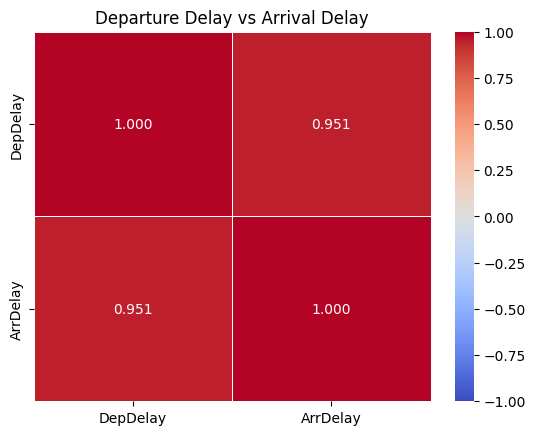

In [53]:
# Departure Delay vs Arrival Delay using heatmap

sns.heatmap(Dep_Arr_Corr, annot=True, cmap='coolwarm', fmt='.3f', vmin=-1, vmax=1, linewidths=0.5)
plt.title('Departure Delay vs Arrival Delay')
plt.show()

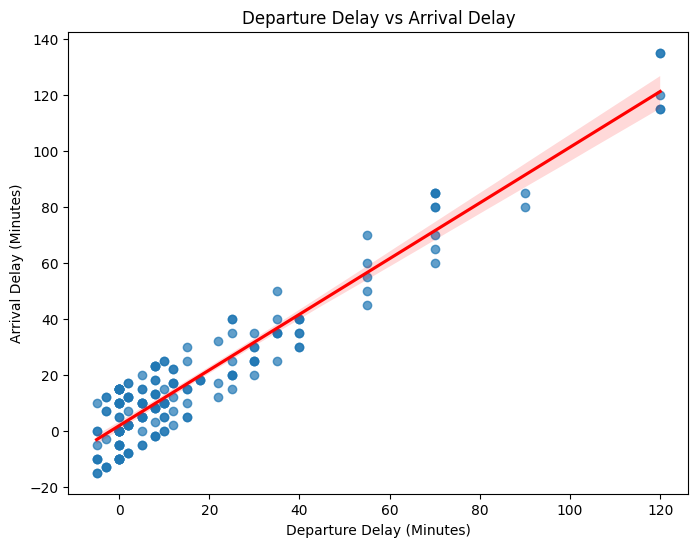

In [65]:
# Scatter Chart to find Departure Delay vs Arrival Delay

plt.figure(figsize=(8, 6))
sns.regplot( data=flight_data, x='DepDelay', y='ArrDelay', scatter_kws={'alpha': 0.7}, line_kws={'color': 'red'} )
plt.title('Departure Delay vs Arrival Delay')
plt.xlabel('Departure Delay (Minutes)')
plt.ylabel('Arrival Delay (Minutes)')
plt.show()

**Relationship Between Departure and Arrival Delays**

The correlation analysis shows a strong positive relationship between departure delay and arrival delay, with a correlation coefficient of approximately 0.951.

**Business Insight:** Flights that depart late tend to arrive late as well. This suggests that reducing departure delays may help improve arrival punctuality. However, the correlation does not prove causation, and some flights may recover time during the journey.

### 6. Which airlines have the highest cancellation rates ?
**Answer :-**

In [55]:
# Which airlines have the highest cancellation rates ?

(flight_data.groupby("Airline")["Cancelled"].mean() * 100).round(2)

Airline
Air India        2.94
AirAsia India    3.57
Akasa Air        0.00
Go First         4.00
IndiGo           4.00
SpiceJet         3.33
Vistara          0.00
Name: Cancelled, dtype: float64

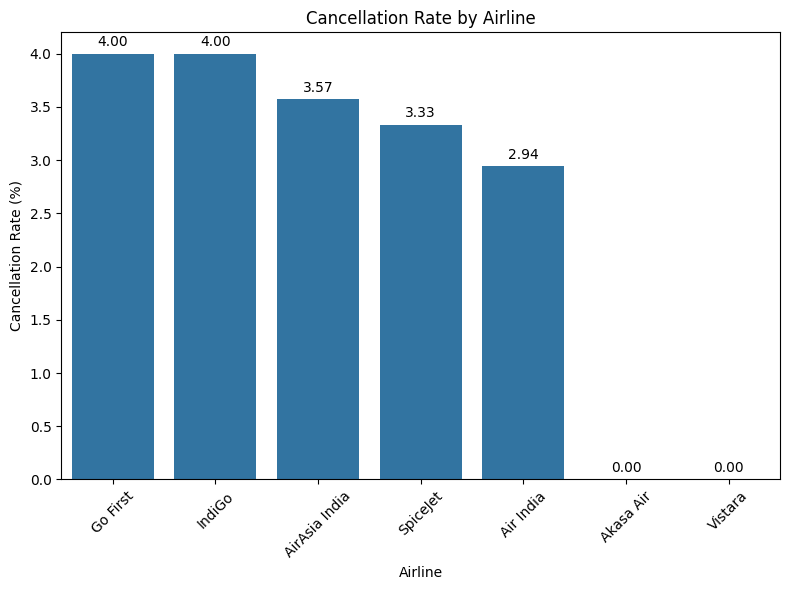

In [56]:
# Cancellation Rate by Airline using Bar chart

airline_cancel = ( flight_data.groupby('Airline')['Cancelled'].mean().mul(100).sort_values(ascending=False).reset_index(name='Cancellation Rate'))

plt.figure(figsize=(8, 6))
sns.barplot(data=airline_cancel, x='Airline', y='Cancellation Rate')

plt.title('Cancellation Rate by Airline')
plt.xlabel('Airline')
plt.ylabel('Cancellation Rate (%)')
plt.xticks(rotation=45)
plt.tight_layout()
for container in plt.gca().containers:
    plt.gca().bar_label(container, fmt='%.2f', padding=3)
plt.show()

**Airline-wise Cancellation Rate Analysis**

The analysis shows that Go First and IndiGo recorded the highest cancellation rates, at 4.00% each. AirAsia India followed at 3.57%, while SpiceJet and Air India recorded cancellation rates of 3.33% and 2.94%, respectively. Akasa Air and Vistara had no recorded cancellations in the dataset.

**Business Insight:** Cancellation rates varied across airlines. Go First and IndiGo may warrant further investigation into their cancellation patterns. However, these results reflect only the available dataset, and airlines with different numbers of recorded flights should be compared cautiously.

### 7. Does flight distance relate to airtime ?
**Answer :-**

In [57]:
# Does flight distance relate to airtime ?

Dist_time_corr = flight_data[["Distance_KM","AirTime_Min"]].corr()
Dist_time_corr

,Distance_KM,AirTime_Min
Distance_KM,1.000000,0.999969
AirTime_Min,0.999969,1.000000


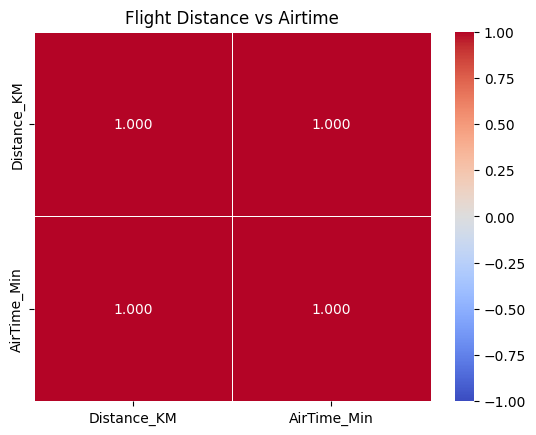

In [64]:
# Flight Distance vs Airtime in heatmap

sns.heatmap(Dist_time_corr, annot=True, cmap='coolwarm', fmt='.3f', vmin=-1, vmax=1, linewidths=0.5)
plt.title("Flight Distance vs Airtime")
plt.show()

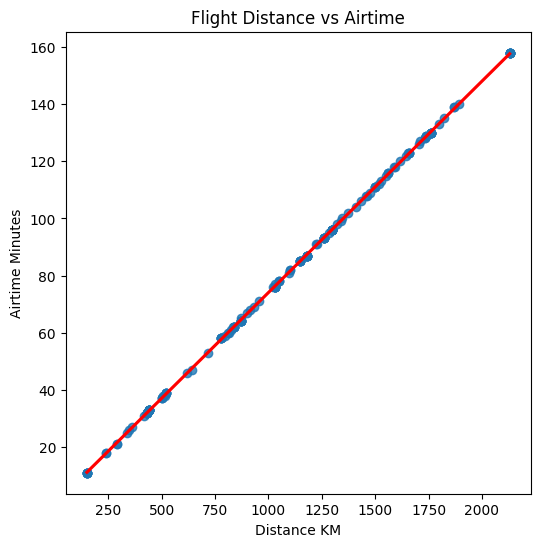

In [63]:
# Scatter Chart to find Flight Distance vs Airtime

plt.figure(figsize = (6,6))
sns.regplot(data = flight_data, x = "Distance_KM", y = "AirTime_Min", line_kws={'color': 'red'})
plt.title("Flight Distance vs Airtime")
plt.xlabel("Distance KM")
plt.ylabel("Airtime Minutes")
plt.show()

**Relationship Between Flight Distance and Airtime**

The correlation analysis showed an extremely strong positive relationship between flight distance and airtime, with a correlation coefficient of **0.999969**. This indicates that flights covering longer distances generally have longer airtimes, while shorter-distance flights tend to have shorter airtimes.

**Business Insight:** Flight distance can be a strong indicator of expected airtime. This relationship can help with flight-duration estimation and scheduling. However, actual airtime may also be influenced by factors such as wind conditions, flight routes, and aircraft type.

### 8. Which routes have the highest average arrival delays ?
**Answer :-**

In [62]:
# Which routes have the highest average arrival delays ?

route_delay = flight_data.groupby(['OriginCity', 'DestCity']).agg(Total_Flights = ('FlightNumber', 'count'), Avg_ArrDelay = ('ArrDelay', 'mean')).reset_index()

route_delay = route_delay[ route_delay['Total_Flights'] >= 5].dropna(subset=['Avg_ArrDelay'])

top_routes = route_delay.nlargest(10, 'Avg_ArrDelay')

top_routes.round(2)

,OriginCity,DestCity,Total_Flights,Avg_ArrDelay
23,Delhi,Hyderabad,6,35.33
64,Mumbai,Ahmedabad,5,28.60
74,Mumbai,Pune,6,26.33
73,Mumbai,Lucknow,6,24.00
65,Mumbai,Bengaluru,6,18.33
25,Delhi,Kochi,9,14.11
66,Mumbai,Chennai,9,13.89
21,Delhi,Chennai,8,12.33
19,Delhi,Ahmedabad,5,11.40
26,Delhi,Kolkata,6,11.33


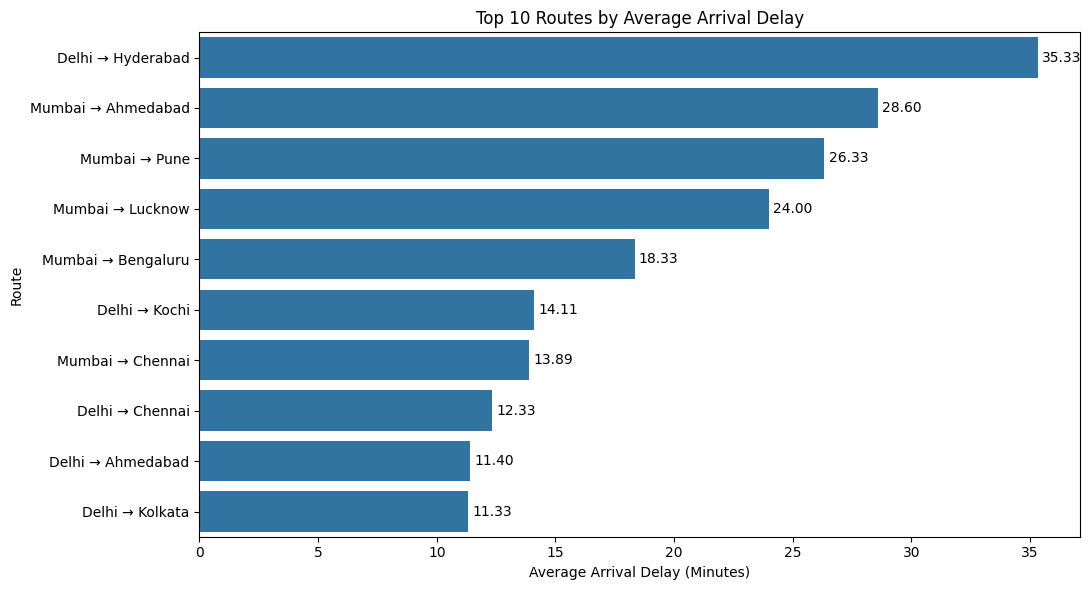

In [61]:
# Bar Chart to find Top 10 Routes by Average Arrival Delay

route_delay = flight_data.groupby(['OriginCity', 'DestCity']).agg( Total_Flights = ('FlightNumber', 'count'), Avg_ArrDelay = ('ArrDelay', 'mean')).reset_index()

route_delay = route_delay[ route_delay['Total_Flights'] >= 5].dropna(subset=['Avg_ArrDelay'])

top_routes = route_delay.nlargest(10, 'Avg_ArrDelay').copy()
top_routes['Route'] = top_routes['OriginCity'] + ' → ' + top_routes['DestCity']

plt.figure(figsize=(11, 6))
sns.barplot(data=top_routes, y='Route', x='Avg_ArrDelay')

plt.title('Top 10 Routes by Average Arrival Delay')
plt.xlabel('Average Arrival Delay (Minutes)')
plt.ylabel('Route')
plt.tight_layout()
for container in plt.gca().containers:
    plt.gca().bar_label(container, fmt='%.2f', padding=3)
plt.show()

**Route-wise Average Arrival Delay Analysis**

The analysis identified the routes with the highest average arrival delays, considering only routes with at least five recorded flights. The Delhi–Hyderabad route recorded the highest average arrival delay of **35.33 minutes across 6 flights**. Mumbai–Ahmedabad followed with an average delay of **28.60 minutes across 5 flights**, while Mumbai–Pune recorded an average delay of **26.33 minutes across 6 flights**.

Other routes with relatively high average arrival delays included Mumbai–Lucknow (24.00 minutes) and Mumbai–Bengaluru (18.33 minutes).

**Business Insight:** These results highlight routes that may require closer monitoring to improve schedule reliability and passenger experience. The Delhi–Hyderabad and Mumbai–Ahmedabad routes could be prioritized for further investigation. However, the results are based on a limited number of flights per route and do not establish the causes of delays.

## Conclusion

The Flight Delay Analysis project explored flight delays, cancellation patterns, airline performance, weekday trends, route-level arrival delays, and the relationship between flight distance and airtime using Python.

The analysis found that AirAsia India had the highest average departure and arrival delays among the airlines in the dataset. Wednesday recorded the highest average arrival delay among the days analyzed, while Monday recorded the lowest. The Delhi–Hyderabad route had the highest average arrival delay among routes with at least five recorded flights. Departure and arrival delays showed a strong positive correlation, while flight distance and airtime had an almost perfect positive correlation.

These findings can help identify delay-prone routes and periods that warrant further investigation. The results describe patterns in the available dataset and do not establish the underlying causes of delays.